In [4]:
#Nama Farel Azkira Pratama
#NIM: 2411513013
#Tugas 2 Pemorgraman pararel

In [1]:
#nomor 1 tanpa lock
import threading
import sys

# Saldo awal rekening
saldo = 1_000_000

# Memperbesar peluang terjadinya perpindahan thread
sys.setswitchinterval(1e-6)

# Fungsi transaksi tanpa Lock
def transaksi():
    global saldo
    for _ in range(10000):
        saldo -= 1
        saldo += 1

# Membuat 10 thread
threads = []
for i in range(10):
    t = threading.Thread(target=transaksi)
    threads.append(t)
    t.start()

# Menunggu semua thread selesai
for t in threads:
    t.join()

# Menampilkan saldo akhir
print("Saldo awal  : Rp1.000.000")
print("Saldo akhir : Rp", saldo)

Saldo awal  : Rp1.000.000
Saldo akhir : Rp 1000000


In [2]:
#nomor 1 dengan lock
import threading
import time
import sys

saldo = 1_000_000
sys.setswitchinterval(1e-6)

def transaksi():
    global saldo
    for _ in range(10000):
        # Penarikan Rp1 (read-modify-write)
        nilai = saldo
        time.sleep(0)
        saldo = nilai - 1

        # Penyetoran Rp1 (read-modify-write)
        nilai = saldo
        time.sleep(0)
        saldo = nilai + 1

threads = []
for i in range(10):
    t = threading.Thread(target=transaksi)
    threads.append(t)
    t.start()

for t in threads:
    t.join()

print("Saldo awal  : Rp1.000.000")
print("Saldo akhir : Rp", saldo)

Saldo awal  : Rp1.000.000
Saldo akhir : Rp 999995


In [1]:
#2 Producer-Consumer dengan Banyak Consumer

import threading
import queue
import time

q = queue.Queue()

def producer():
    for i in range(1, 21):
        print(f"Producer menghasilkan data: {i}")
        q.put(i)
        time.sleep(0.1)

    for _ in range(3):
        q.put(None)

    print("Producer selesai.")

def consumer(nama):
    while True:
        data = q.get()

        if data is None:
            print(f"{nama} menerima sinyal berhenti.")
            q.task_done()
            break

        print(f"{nama} memproses data: {data}")
        time.sleep(0.2)

        q.task_done()

    print(f"{nama} selesai.")

consumers = []
for i in range(1, 4):
    t = threading.Thread(target=consumer, args=(f"Consumer {i}",))
    consumers.append(t)
    t.start()

p = threading.Thread(target=producer)
p.start()

p.join()

q.join()

for t in consumers:
    t.join()

print("Semua proses selesai.")

Producer menghasilkan data: 1
Consumer 1 memproses data: 1
Producer menghasilkan data: 2
Consumer 2 memproses data: 2
Producer menghasilkan data: 3
Consumer 3 memproses data: 3
Producer menghasilkan data: 4
Consumer 1 memproses data: 4
Producer menghasilkan data: 5
Consumer 2 memproses data: 5
Producer menghasilkan data: 6
Consumer 3 memproses data: 6
Producer menghasilkan data: 7
Consumer 1 memproses data: 7
Producer menghasilkan data: 8
Consumer 2 memproses data: 8
Producer menghasilkan data: 9
Consumer 3 memproses data: 9
Producer menghasilkan data: 10
Consumer 1 memproses data: 10
Producer menghasilkan data: 11
Consumer 2 memproses data: 11
Producer menghasilkan data: 12
Consumer 3 memproses data: 12
Producer menghasilkan data: 13
Consumer 1 memproses data: 13
Producer menghasilkan data: 14
Consumer 2 memproses data: 14
Producer menghasilkan data: 15
Consumer 3 memproses data: 15
Producer menghasilkan data: 16
Consumer 1 memproses data: 16
Producer menghasilkan data: 17
Consumer 2 

max_workers = 2
Jumlah file = 50
Total karakter = 175000
Waktu rata-rata = 1.3115 detik
-----------------------------------
max_workers = 4
Jumlah file = 50
Total karakter = 175000
Waktu rata-rata = 0.6791 detik
-----------------------------------
max_workers = 8
Jumlah file = 50
Total karakter = 175000
Waktu rata-rata = 0.3681 detik
-----------------------------------
max_workers = 16
Jumlah file = 50
Total karakter = 175000
Waktu rata-rata = 0.2151 detik
-----------------------------------


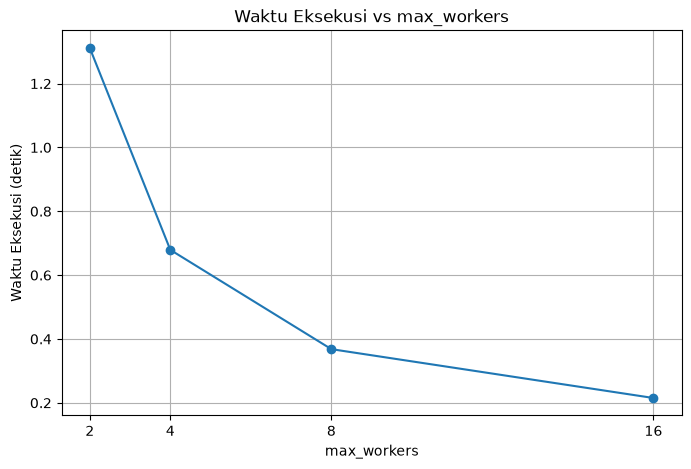

In [2]:
#3 Eksperimen ThreadPoolExecutor
import os
import time
import tempfile
import statistics
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import matplotlib.pyplot as plt

jumlah_file = 50
ukuran_data = "Data eksperimen ThreadPoolExecutor\n" * 100

def proses_file(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        data = file.read()

    time.sleep(0.05)

    return len(data)

daftar_workers = [2, 4, 8, 16]
waktu_eksekusi = []

with tempfile.TemporaryDirectory() as folder:
    daftar_file = []

    for i in range(jumlah_file):
        path = Path(folder) / f"file_{i+1}.txt"
        path.write_text(ukuran_data, encoding="utf-8")
        daftar_file.append(path)

    for workers in daftar_workers:
        hasil_waktu = []

        for percobaan in range(3):
            mulai = time.perf_counter()

            with ThreadPoolExecutor(max_workers=workers) as executor:
                hasil = list(executor.map(proses_file, daftar_file))

            selesai = time.perf_counter()
            durasi = selesai - mulai
            hasil_waktu.append(durasi)

        rata_rata = statistics.mean(hasil_waktu)
        waktu_eksekusi.append(rata_rata)

        print(f"max_workers = {workers}")
        print(f"Jumlah file = {len(hasil)}")
        print(f"Total karakter = {sum(hasil)}")
        print(f"Waktu rata-rata = {rata_rata:.4f} detik")
        print("-" * 35)

plt.figure(figsize=(8, 5))
plt.plot(daftar_workers, waktu_eksekusi, marker="o")
plt.title("Waktu Eksekusi vs max_workers")
plt.xlabel("max_workers")
plt.ylabel("Waktu Eksekusi (detik)")
plt.xticks(daftar_workers)
plt.grid(True)
plt.show()

In [5]:
#4 Refleksi Singkat
#Contoh Kasus Threading Python
#Threading Python dapat membantu pada aplikasi server yang menangani banyak permintaan pengguna 
#secara bersamaan. Misalnya, ketika server membaca file atau menunggu respons dari database
#thread lain dapat tetap bekerja tanpa harus menunggu proses tersebut selesai. Hal ini membuat
#penggunaan waktu menjadi lebih efisien, terutama pada pekerjaan yang bersifat I/O-bound.

#Contoh Kasus Multiprocessing Python

#Threading Python kurang efektif untuk pekerjaan yang membutuhkan komputasi berat, seperti mengolah 
#data berukuran besar atau melakukan perhitungan matematis yang kompleks. Hal ini disebabkan oleh
#Global Interpreter Lock (GIL) pada CPython yang membatasi eksekusi bytecode Python secara bersamaan 
#dalam banyak thread. Untuk kasus tersebut, multiprocessing lebih sesuai karena menggunakan proses 
#terpisah yang dapat berjalan pada beberapa inti CPU, sehingga komputasi dapat dilakukan secara
#paralel.
